# Predicción de la posición final de Max Verstappen

Equipo: Iván Moros / Juan Daniel Cuervo

In [1]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


## 0. Funciones (las mismas de `model.py`)

En Colab no tenemos `model.py`, por eso copiamos las funciones aquí.

In [2]:
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import os
# Si no está la carpeta data/, se descarga de Kaggle
path = 'data/f1_enhanced_dataset_for_analysis.csv'
if not os.path.exists(path):
  import kagglehub
  path = kagglehub.dataset_download('usman136/formula-1-race-dataset-for-predictive-analysis') + '/f1_enhanced_dataset_for_analysis.csv'

def load_data():
  df = pd.read_csv(path)
  return df[df['Driver'] == 'Max Verstappen']

def preprocessing(df):
  # quitamos los abandonos (DNF) porque no son una posicion real de llegada
  df = df[df['DNF'] != 1]
  # solo datos que se saben antes de la carrera
  X = df[['Year', 'Location', 'Weather', 'StartPosition', 'QualifyingPosition']]
  y = df['FinishPosition']
  X = pd.get_dummies(X, columns=['Location', 'Weather'])
  return X, y

def train(X, y, name):
  if name == 'Regresión Lineal':
    model = LinearRegression()
  elif name == 'Árbol de Decisión':
    model = DecisionTreeRegressor(max_depth=5, random_state=42)
  else:
    model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
  model.fit(X, y)
  return model

def evaluate(y_true, y_pred):
  mae = mean_absolute_error(y_true, y_pred)
  mse = mean_squared_error(y_true, y_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_true, y_pred)
  return mae, mse, rmse, r2

def predict(model, X_columns, year, location, weather, quali, start):
  row = pd.DataFrame({'Year': [year], 'Location': [location], 'Weather': [weather],
                      'StartPosition': [start], 'QualifyingPosition': [quali]})
  row = pd.get_dummies(row, columns=['Location', 'Weather'])
  # un circuito nuevo no esta en el entrenamiento, queda en 0
  row = row.reindex(columns=X_columns, fill_value=0)
  pred = round(model.predict(row)[0])
  return int(np.clip(pred, 1, 20))


## 1. Cargar datos

Leemos el CSV completo (6000 filas) y nos quedamos solo con las filas de Max Verstappen.

In [3]:
df_all = pd.read_csv(path)
print('Dataset completo:', df_all.shape)
df = load_data()
print('Filas de Verstappen:', df.shape)

Dataset completo: (6000, 17)
Filas de Verstappen: (300, 17)


## 2. Limpieza

Revisamos nulos y duplicados, quitamos los abandonos (DNF) y dejamos solo las columnas que se saben antes de la carrera.

In [4]:
print('Valores nulos:', df.isnull().sum().sum())
print('Duplicados:', df.duplicated().sum())
print('Filas con DNF (abandonos) que se quitan:', (df['DNF'] == 1).sum())
# Se usan solo 5 columnas: las demás (Points, RaceTime_sec, etc.) se saben hasta después de la carrera
X, y = preprocessing(df)
print('Forma final de X:', X.shape)

Valores nulos: 0
Duplicados: 0
Filas con DNF (abandonos) que se quitan: 20
Forma final de X: (280, 37)


## 3. Exploración

Miramos las variables con gráficas y correlaciones para entender qué se relaciona con la posición final.

           RaceID         Year  StartPosition  FinishPosition  \
count  280.000000   280.000000     280.000000      280.000000   
mean   152.353571  2016.807143      10.567857        9.960714   
std     86.787922     4.403316       5.461075        6.406361   
min      1.000000  2010.000000       1.000000        1.000000   
25%     77.750000  2013.000000       6.000000        4.000000   
50%    153.500000  2017.000000      10.000000       10.000000   
75%    227.250000  2020.000000      15.000000       16.000000   
max    300.000000  2024.000000      20.000000       20.000000   

       FastestLapTime_sec    DNF      Points  PitStopCount  \
count          280.000000  280.0  280.000000    280.000000   
mean            95.253032    0.0   16.039286      2.128571   
std              5.305419    0.0    6.406361      0.797333   
min             77.246000    0.0    6.000000      1.000000   
25%             91.582500    0.0   10.000000      2.000000   
50%             95.322500    0.0   16.0000

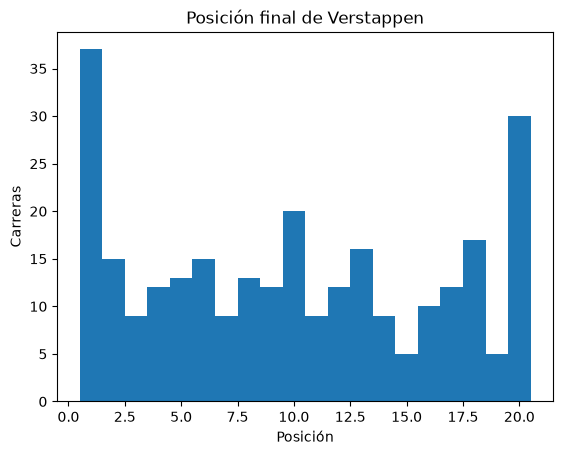

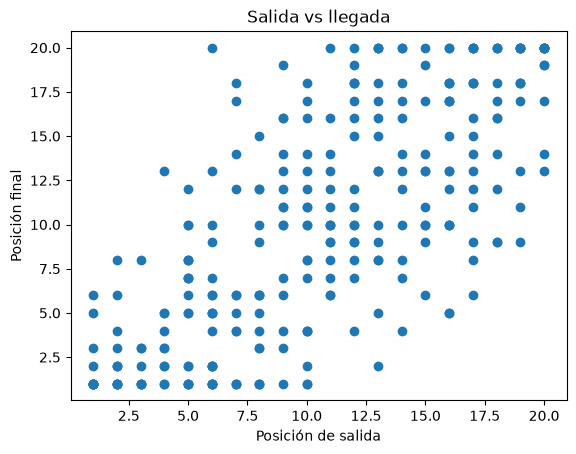

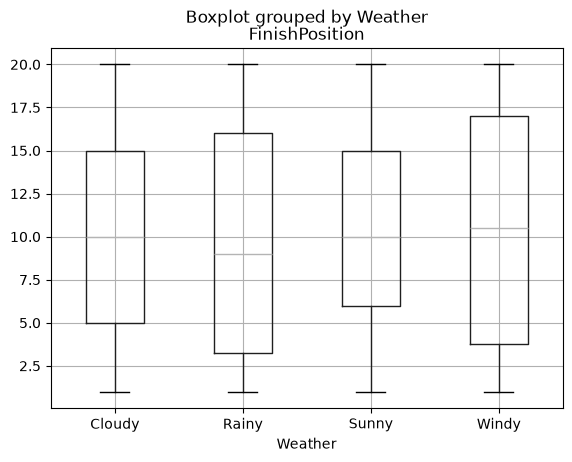

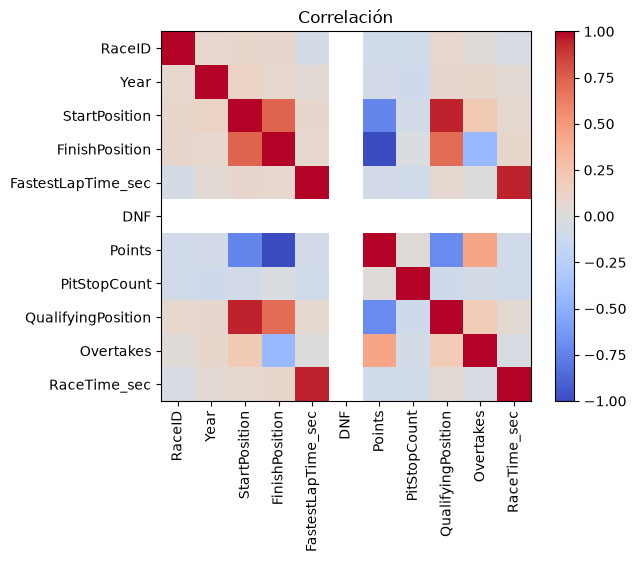

Corr StartPosition: 0.730791527464769
Corr QualifyingPosition: 0.6953512894676693


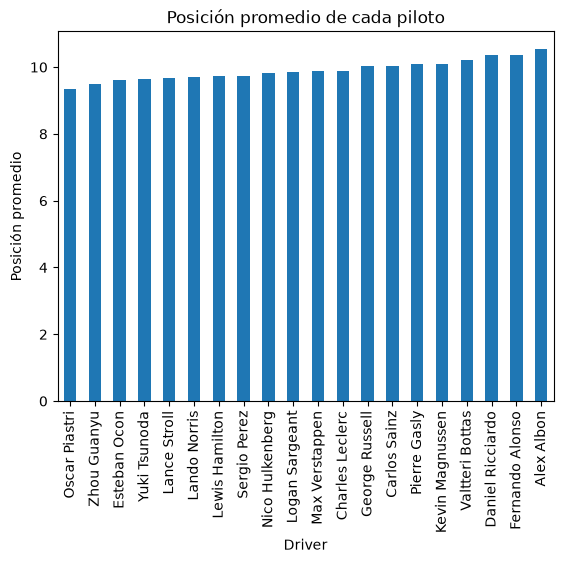

In [5]:
clean = df[df['DNF'] != 1]
print(clean.describe())

plt.hist(clean['FinishPosition'], bins=range(1, 22), align='left')
plt.title('Posición final de Verstappen')
plt.xlabel('Posición')
plt.ylabel('Carreras')
plt.show()

plt.scatter(clean['StartPosition'], clean['FinishPosition'])
plt.title('Salida vs llegada')
plt.xlabel('Posición de salida')
plt.ylabel('Posición final')
plt.show()

clean.boxplot(column='FinishPosition', by='Weather')
plt.show()

corr = clean.select_dtypes(include=['int64', 'float64']).corr()
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title('Correlación')
plt.show()

print('Corr StartPosition:', clean['StartPosition'].corr(clean['FinishPosition']))
print('Corr QualifyingPosition:', clean['QualifyingPosition'].corr(clean['FinishPosition']))

mean_pos = df_all.groupby('Driver')['FinishPosition'].mean().sort_values()
mean_pos.plot(kind='bar')
plt.title('Posición promedio de cada piloto')
plt.ylabel('Posición promedio')
plt.show()

## 4. PCA

Separamos entrenamiento y prueba, y vemos con PCA cuántos componentes hacen falta para explicar el 90% de la varianza.

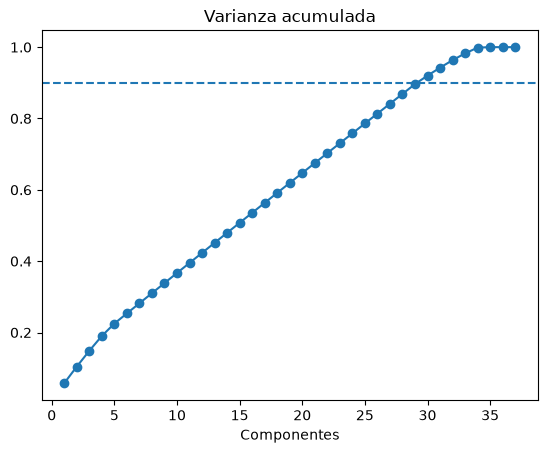

Componentes para 90% de varianza: 30 de 37
Varianza explicada: 0.920120366054692


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pca = PCA().fit(StandardScaler().fit_transform(X_train))
cum_var = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.9, linestyle='--')
plt.title('Varianza acumulada')
plt.xlabel('Componentes')
plt.show()

n = int(np.argmax(cum_var >= 0.9)) + 1
print('Componentes para 90% de varianza:', n, 'de', X.shape[1])
print('Varianza explicada:', cum_var[n - 1])

## 5. Modelos

Entrenamos los 3 modelos, con y sin PCA, y los comparamos con validación cruzada. También calculamos dos reglas simples.

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for use_pca in [False, True]:
  for name in ['Regresión Lineal', 'Árbol de Decisión', 'Random Forest']:
    model = train(X_train, y_train, name)
    if use_pca:
      model = make_pipeline(StandardScaler(), PCA(n), clone(model)).fit(X_train, y_train)
    cv = -cross_val_score(clone(model), X_train, y_train, cv=kf,
                          scoring='neg_mean_absolute_error').mean()
    train_mae = evaluate(y_train, model.predict(X_train))[0]
    mae, mse, rmse, r2 = evaluate(y_test, model.predict(X_test))
    rows.append({'modelo': name, 'pca': 'si' if use_pca else 'no', 'cv_MAE': cv,
                 'train_MAE': train_mae, 'test_MAE': mae, 'test_MSE': mse,
                 'test_RMSE': rmse, 'test_R2': r2})

# Reglas simples: terminar donde salió y siempre el promedio
pred_train = X_train['StartPosition']
pred_test = X_test['StartPosition']
mae, mse, rmse, r2 = evaluate(y_test, pred_test)
simple_mae = evaluate(y_train, pred_train)[0]
rows.append({'modelo': 'termina donde salió', 'pca': '-', 'cv_MAE': simple_mae,
             'train_MAE': simple_mae, 'test_MAE': mae, 'test_MSE': mse,
             'test_RMSE': rmse, 'test_R2': r2})
mean_train = np.full(len(y_train), y_train.mean())
mean_test = np.full(len(y_test), y_train.mean())
mae, mse, rmse, r2 = evaluate(y_test, mean_test)
mean_mae = evaluate(y_train, mean_train)[0]
rows.append({'modelo': 'siempre el promedio', 'pca': '-', 'cv_MAE': mean_mae,
             'train_MAE': mean_mae, 'test_MAE': mae, 'test_MSE': mse,
             'test_RMSE': rmse, 'test_R2': r2})
results = pd.DataFrame(rows)

## 6. Resultados

Mostramos la tabla de resultados y una gráfica comparando el error de cada modelo contra la regla "termina donde salió".

             modelo pca  cv_MAE  train_MAE  test_MAE  test_MSE  test_RMSE  test_R2
   Regresión Lineal  no    4.03       3.44      3.54     19.52       4.42     0.33
  Árbol de Decisión  no    4.59       2.90      3.57     23.84       4.88     0.19
      Random Forest  no    4.08       2.90      3.23     16.74       4.09     0.43
   Regresión Lineal  si    4.11       3.56      3.08     15.73       3.97     0.46
  Árbol de Decisión  si    4.85       2.46      3.99     25.74       5.07     0.12
      Random Forest  si    4.23       2.48      3.57     20.03       4.48     0.32
termina donde salió   -    3.57       3.57      3.14     17.29       4.16     0.41
siempre el promedio   -    5.75       5.75      4.72     31.59       5.62    -0.08
Mejor modelo por cv_MAE: Regresión Lineal (PCA: no) 4.03
MAE de la regla simple (termina donde salió): 3.57


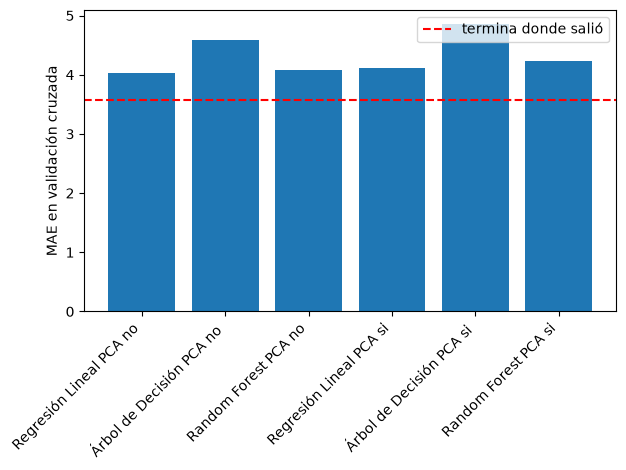

In [8]:
print(results.round(2).to_string(index=False))
models = results[results['pca'] != '-']
best = models.loc[models['cv_MAE'].idxmin()]
print('Mejor modelo por cv_MAE:', best['modelo'], '(PCA:', best['pca'] + ')', round(best['cv_MAE'], 2))
print('MAE de la regla simple (termina donde salió):', round(simple_mae, 2))

labels = models['modelo'] + ' PCA ' + models['pca']
plt.bar(labels, models['cv_MAE'])
plt.axhline(simple_mae, color='red', linestyle='--', label='termina donde salió')
plt.xticks(rotation=45, ha='right')
plt.ylabel('MAE en validación cruzada')
plt.legend()
plt.tight_layout()
plt.show()

# Conclusión:
# - En validación cruzada ningún modelo le gana a "termina donde salió".
# - Usar PCA empeoró a todos los modelos.
# - Los árboles sobreajustan: su error de entrenamiento es mucho menor que el de validación cruzada.
# - Los datos parecen sintéticos (Verstappen queda casi en el promedio de todos los pilotos).

## Conclusiones

- Con validación cruzada el mejor modelo fue la Regresión Lineal sin PCA (MAE 4.03 posiciones), pero la regla simple "termina donde salió" tiene MAE 3.57, o sea que ningún modelo le gana.
- Usar PCA empeoró a los tres modelos en validación cruzada (por ejemplo, el Random Forest pasó de 4.08 a 4.23).
- El árbol y el Random Forest sobreajustan: en entrenamiento se equivocan 2.9 posiciones y en validación cruzada 4.1 a 4.6.
- En el conjunto de prueba la regresión lineal con PCA salió mejor (MAE 3.08 contra 3.14 de la regla simple), pero con solo 56 carreras de prueba esa diferencia es ruido.
- La posición de salida (correlación 0.73) y la de clasificación (0.70) son lo que más se relaciona con la llegada.

## Limitaciones

- Son pocos datos: 280 carreras de un solo piloto.
- Los datos parecen sintéticos: Verstappen queda casi en el promedio de todos los pilotos, algo raro para un campeón.
- Solo usamos información de antes de la carrera, así que no se puede predecir lo que pasa durante ella (abandonos, lluvia repentina, etc.).
- La prueba es chica (56 carreras), por eso el MAE de prueba cambia mucho de un modelo a otro.